![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# Two-Source Energy Balance: Separating Soil Evaporation and Transpiration

A Landsat thermal pixel over an orchard or a young row crop sees a mix of sunlit canopy and hot,
often dry, soil. One-source models such as SEBAL and METRIC treat that mix as one surface with one
temperature and one resistance, and absorb the difference between the mix and the canopy into the
anchor calibration. The two-source energy balance (TSEB) of Norman et al. (1995) instead splits the
pixel into a soil and a canopy component, each with its own temperature, net radiation and fluxes.
That makes it suitable for partial canopies, and it separates evaporation from the soil from
transpiration by the plants, which matters for water productivity and irrigation efficiency. This
notebook runs TSEB with the Priestley-Taylor start (TSEB-PT) on the 5 July 2024 scene, maps soil and
canopy temperatures and the transpiration fraction, compares it with METRIC, and shows its main
sensitivity, the air temperature.

## Overview

### Splitting the radiometric temperature

The thermal sensor measures one radiometric temperature `Trad`. TSEB writes it as an emission-
weighted mix of canopy temperature `Tc` and soil temperature `Ts`:

`Trad^4 = f_theta Tc^4 + (1 - f_theta) Ts^4`, with `f_theta = 1 - exp(-0.5 Omega LAI / cos(theta_v))`

`f_theta` is the fraction of the view filled by vegetation at view angle `theta_v` (Landsat looks
almost straight down) and `Omega` a clumping factor (1 for a random canopy, below 1 for rows and
orchards).

### Splitting net radiation

Net radiation is shared between canopy and soil with an extinction law,
`Rn_s = Rn exp(-kappa Omega LAI / sqrt(2 cos(theta_s)))`, `Rn_c = Rn - Rn_s`, with `kappa` about
0.45 and `theta_s` the sun zenith angle. Soil heat flux is a fraction of the soil's net radiation,
`G = 0.35 Rn_s`.

### The Priestley-Taylor start

The canopy is first assumed to transpire at the Priestley-Taylor rate,
`LE_c = alpha_PT fg Delta / (Delta + gamma) Rn_c` with `alpha_PT = 1.26` (unstressed). Then:

1. `H_c = Rn_c - LE_c`, and `Tc` follows from `H_c = rho cp (Tc - Ta) / rah`.
2. `Ts` follows from the radiometric split.
3. `H_s = rho cp (Ts - Ta) / (rah + rs)`, with the soil resistance `rs` of Kustas and Norman (1999),
   which depends on the wind near the soil and the temperature difference between soil and canopy.
4. `LE_s = Rn_s - G - H_s`.

If `LE_s` comes out negative, which is impossible during the day, the canopy is stressed: `alpha_PT`
is lowered step by step until `LE_s` is zero or positive. If it reaches zero, the canopy is not
transpiring at all.

### Parallel and series networks

In the **parallel** network (used here) soil and canopy exchange heat with the air above the canopy
independently. The **series** network lets both exchange heat with the air inside the canopy space,
which then exchanges with the air above; it is more realistic for dense canopies and needs more
resistances. `pyTSEB` (Nieto et al.) implements both, together with many refinements.

### ALEXI and DisALEXI

TSEB needs the air temperature `Ta`, and it is sensitive to it: an error of 1 K in `Ta` changes `H`
over a hot surface by tens of W m-2. ALEXI (Anderson et al. 1997) removes that dependence by using
the rise in surface temperature between early morning and midday from geostationary satellites,
coupled to a model of the growing atmospheric boundary layer. DisALEXI then disaggregates the coarse
ALEXI fluxes to Landsat resolution by adjusting the air temperature until the Landsat TSEB fluxes
match the ALEXI ones; this is the OpenET member of the family.

## TSEB with GeoLattice

| Function | Purpose |
|---|---|
| `seb.tseb_pt(lst, lai, t_air, u, ea, pressure, rn, sza, hc=, z_u=, z_t=, ...)` | TSEB-PT with a parallel network; returns soil and canopy net radiation, `G`, `H` and `LE`, temperatures and T/ET |
| `seb.partition_et(le_c, le_s)` | transpiration fraction |
| `seb.fractional_cover`, `seb.leaf_area_index` | canopy structure |

### Learning objectives

1. Explain how TSEB splits radiometric temperature and net radiation between soil and canopy.
2. Describe the Priestley-Taylor start and how the model reduces `alpha_PT` under stress.
3. Run TSEB-PT on a Landsat scene and map soil and canopy temperatures, soil evaporation and
   transpiration.
4. Relate the transpiration fraction to vegetation cover and crop type.
5. Compare TSEB with METRIC and measure TSEB's sensitivity to air temperature.

### Data

The 5 July 2024 Landsat 8 scene (`sd.load_scene`), its net radiation and LAI (`sd.energy_inputs`),
the ERA5 air temperature, humidity and wind at the overpass, and the METRIC result of notebook 06.
Canopy heights come from a crop table (illustrative values, as in notebook 04).

### Contents

- Setup
- Canopy structure
- Running TSEB-PT
- Soil and canopy temperatures
- Evaporation and transpiration
- TSEB and METRIC
- Sensitivity to air temperature
- An optional check with pyTSEB
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

ds = sd.load_scene()  # Landsat 8, 5 July 2024
p = sd.energy_inputs(ds)  # LST, LAI, Rn, pressure
a = ds.attrs  # overpass weather
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent
path = OUT / "metric_20240705.nc"  # METRIC result of notebook 06
metric = xr.open_dataset(path).load() if path.exists() else sd.run_metric_scene(ds, p)  # read or recompute
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().select_dtypes("number").dropna()  # one row per pixel
    return pd.DataFrame({g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean()
                         for g, c in GROUPS.items()}).T  # group means

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Canopy structure

TSEB needs LAI (from SAVI, notebook 03) and canopy height. Heights come from the crop map; the
clumping factor is set to 0.7 for orchards and vineyards, whose canopies are concentrated in rows,
and 1 elsewhere.

In [2]:
HEIGHT = {75: 4.0, 204: 3.5, 76: 6.0, 211: 4.0, 212: 4.0, 217: 3.0, 69: 1.8, 54: 0.6, 2: 1.0, 1: 2.0,
          36: 0.5, 208: 0.3, 24: 0.1, 21: 0.1, 51: 0.4, 61: 0.1, 176: 0.2, 152: 0.5}  # illustrative canopy heights (m)
ROWS = [75, 204, 76, 211, 212, 217, 69]  # orchards and vineyards
hc = xr.full_like(p["lai"], 0.5)  # default height 0.5 m
for code, h in HEIGHT.items():  # every class with a height
    hc = hc.where(ds.cdl != code, h)  # set its height
clump = xr.where(ds.cdl.isin(ROWS), 0.7, 1.0)  # clumping factor
lai = p["lai"]  # LAI from SAVI
by_group(lai=lai, height=hc.where(p["mask"]), clumping=clump.where(p["mask"])).round(2)  # per crop group

,lai,height,clumping
Tree crops,1.20,3.67,0.7
Grapes,2.34,1.80,0.7
Annual crops,2.41,0.58,1.0
Fallow,0.04,0.10,1.0
Grass and shrubs,0.22,0.20,1.0
Developed,0.24,0.50,1.0


## Running TSEB-PT

The ERA5 air temperature, vapour pressure and 10 m wind at the overpass drive the model; the sun
zenith angle comes from the scene metadata. TSEB needs its forcing heights above the canopy, so
over the 3.5 to 6 m orchards `seb.tseb_pt` treats the 2 m air temperature as the air 2 m above the
tree tops (heights below `hc + 2` m are raised to it), a common assumption with reanalysis forcing.

In [3]:
t_air = a["t_air_c"] + 273.15  # K
sza = 90 - a["sun_elevation"]  # degrees
ts = seb.tseb_pt(p["lst"], lai, t_air, a["u10"], a["ea_kpa"], p["pressure"], p["rn"], sza,
                 hc=hc, z_u=10.0, z_t=2.0, clumping=clump)  # TSEB-PT, parallel network
closure = float(np.nanmax(np.abs(ts.rn_s + ts.rn_c - ts.g - ts.h_s - ts.h_c - ts.le)))  # energy balance residual
print(f"largest |Rn - G - H - LE|: {closure:.1e} W/m2")  # the balance closes for both sources
by_group(Rn_soil=ts.rn_s, Rn_canopy=ts.rn_c, G=ts.g, H_soil=ts.h_s, H_canopy=ts.h_c,
         LE_soil=ts.le_s, LE_canopy=ts.le_c).round(0)  # per crop group, W/m2

largest |Rn - G - H - LE|: 2.3e-13 W/m2


,Rn_soil,Rn_canopy,G,H_soil,H_canopy,LE_soil,LE_canopy
Tree crops,436.0,130.0,153.0,93.0,-9.0,190.0,140.0
Grapes,342.0,212.0,120.0,59.0,-13.0,164.0,225.0
Annual crops,293.0,226.0,103.0,69.0,2.0,121.0,224.0
Fallow,480.0,4.0,168.0,243.0,-0.0,69.0,5.0
Grass and shrubs,445.0,33.0,156.0,124.0,-2.0,166.0,36.0
Developed,465.0,36.0,163.0,142.0,-2.0,161.0,38.0


Over fallow land almost all net radiation reaches the soil and becomes soil heat and sensible heat.
Over grapes and annual crops (LAI near 2.4) the canopy absorbs about 40 % of the net radiation
(212 to 226 W m-2) and transpires nearly all of it, with canopy `H` close to zero. Orchards absorb
less in the canopy (130 W m-2): with LAI near 1.2 and row clumping, most of the sunlight reaches the
soil between the trees.

## Soil and canopy temperatures

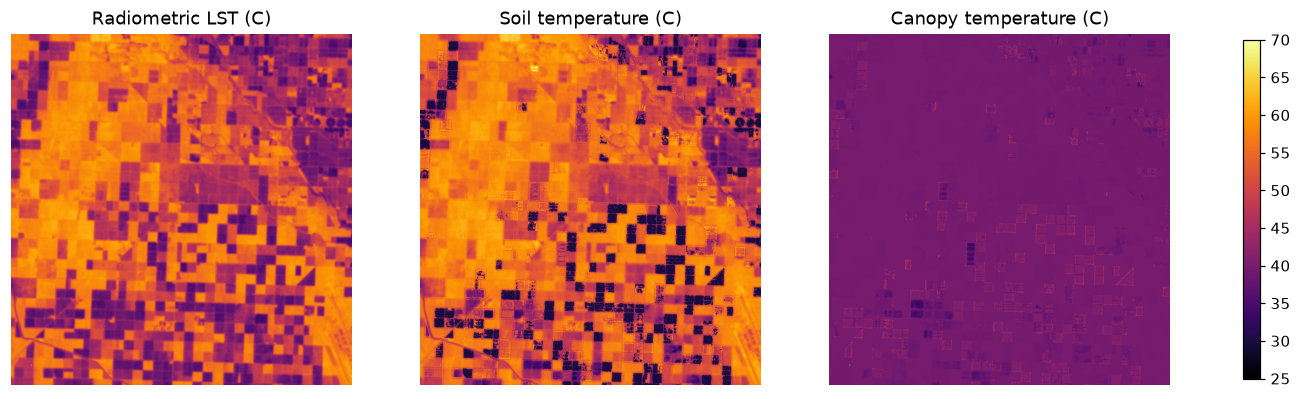

,lst,t_soil,t_canopy
Tree crops,47.7,49.5,39.6
Grapes,44.2,48.7,39.1
Annual crops,46.9,46.9,40.0
Fallow,57.5,57.7,39.8
Grass and shrubs,55.7,57.2,39.7
Developed,53.2,54.4,39.7


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))  # three maps
for a_, v, t in zip(ax, [p["lst"], ts.t_soil, ts.t_canopy], ["Radiometric LST", "Soil temperature", "Canopy temperature"]):  # three temperatures
    im = a_.imshow(v - 273.15, extent=ext, cmap="inferno", vmin=25, vmax=70); a_.set_title(f"{t} (C)"); a_.axis("off")  # map
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()  # shared scale
by_group(lst=p["lst"] - 273.15, t_soil=ts.t_soil - 273.15, t_canopy=ts.t_canopy - 273.15).round(1)  # per crop group, C

The canopy temperature is close to the air temperature (39 to 40 C) in every group, because a
canopy transpiring at the Priestley-Taylor rate has little sensible heat. The radiometric split then
puts the rest of the signal on the soil: under grapes the soil is 48.7 C against an LST of 44.2 C,
and 9 to 18 K hotter than the canopy in the vegetated groups. Over bare fallow land the soil
temperature equals LST.

## Evaporation and transpiration

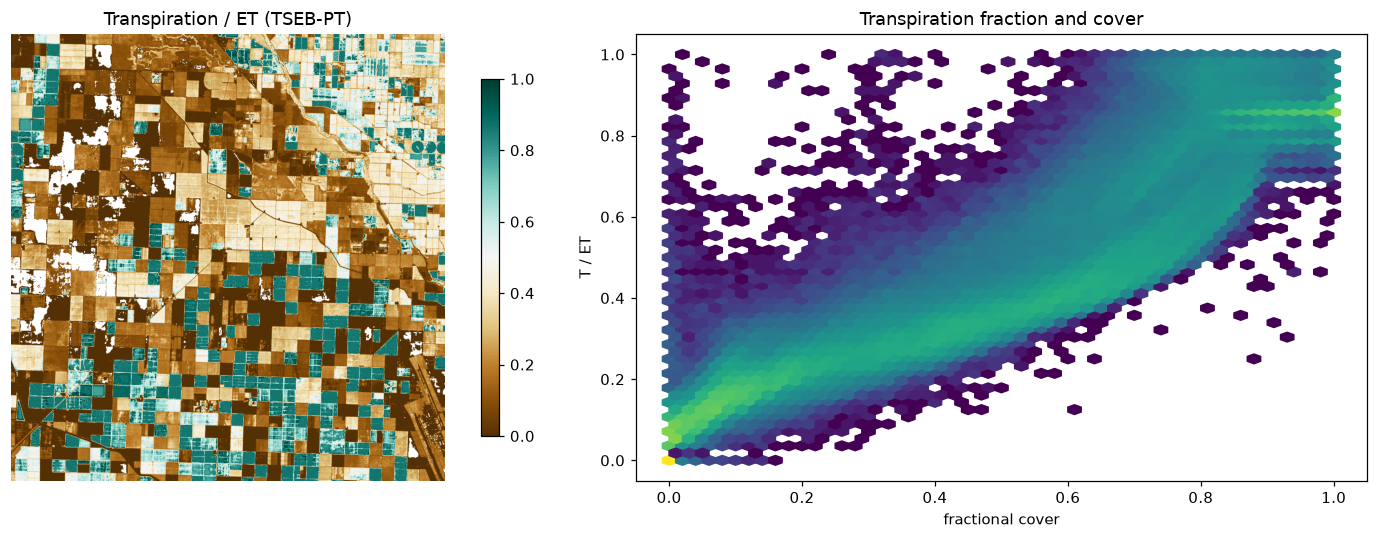

,fractional cover,LE soil,LE canopy,T/ET
Tomatoes,0.91,84.75,416.17,0.86
Cotton,0.72,110.91,289.58,0.73
Grapes,0.68,163.67,224.98,0.52
Almonds,0.66,203.32,211.10,0.44
Pistachios,0.40,183.98,103.45,0.31
Grassland/pasture,0.08,165.23,35.39,0.16
Garlic,0.06,179.06,29.64,0.13
"Developed, low intensity",0.05,163.29,41.63,0.11
Winter wheat,0.01,137.26,16.96,0.09
Fallow/idle cropland,0.00,69.20,4.58,0.00


In [5]:
t_et = seb.partition_et(ts.le_c, ts.le_s)  # transpiration fraction
fc = seb.fractional_cover(p["ndvi"])  # vegetation cover
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # map and scatter
im = ax[0].imshow(t_et, extent=ext, cmap="BrBG", vmin=0, vmax=1); plt.colorbar(im, ax=ax[0], shrink=0.8)  # T/ET map
ax[0].set_title("Transpiration / ET (TSEB-PT)"); ax[0].axis("off")  # title
ax[1].hexbin(fc.values.ravel(), t_et.values.ravel(), gridsize=50, bins="log", extent=(0, 1, 0, 1))  # T/ET vs cover
ax[1].set_xlabel("fractional cover"); ax[1].set_ylabel("T / ET"); ax[1].set_title("Transpiration fraction and cover")  # labels
plt.tight_layout(); plt.show()  # draw
crops = ds.cdl.where(p["mask"]).to_series().value_counts().index[:10]  # the 10 most common classes
pd.DataFrame({sd.cdl_name(c): {"fractional cover": float(fc.where(ds.cdl == c).median()), "LE soil": float(ts.le_s.where(ds.cdl == c).mean()),
                                "LE canopy": float(ts.le_c.where(ds.cdl == c).mean()), "T/ET": float(t_et.where(ds.cdl == c).median())}
              for c in crops}).T.sort_values("T/ET", ascending=False).round(2)  # per crop class

Transpiration dominates ET over dense canopies (T/ET of 0.86 for tomatoes at 91 % cover), and soil
evaporation takes over as cover falls (0.44 for almonds, 0.31 for pistachios). Field studies with
isotopes and sap flow in orchards and vineyards commonly report T/ET of 0.5 to 0.9 depending on
cover and irrigation method (drip irrigation wets less soil than sprinklers or furrows). TSEB has
no information on how the soil was irrigated: it infers soil evaporation only from the energy left
after the soil's sensible heat. The rangeland and developed land show the weakness: TSEB gives them
about 165 W m-2 of soil evaporation, although their soil is dry in July. The soil resistance limits
how much sensible heat the hot soil can lose, and the residual becomes evaporation. Soil
evaporation is the least certain part of a TSEB result, and orchard T/ET here is likely too low.

## TSEB and METRIC

,LE_tseb,LE_metric,H_tseb,H_metric,ET24 TSEB (ETrF x ETr24),ET24 METRIC
Tree crops,329.8,424.8,83.9,42.4,8.3,10.7
Grapes,388.6,499.4,45.7,-14.0,9.8,12.6
Annual crops,345.7,387.7,71.0,43.8,8.7,9.8
Fallow,73.8,103.8,242.6,236.7,1.9,2.7
Grass and shrubs,201.5,156.8,121.2,182.7,5.1,4.1
Developed,199.2,245.0,139.4,123.1,5.1,6.2


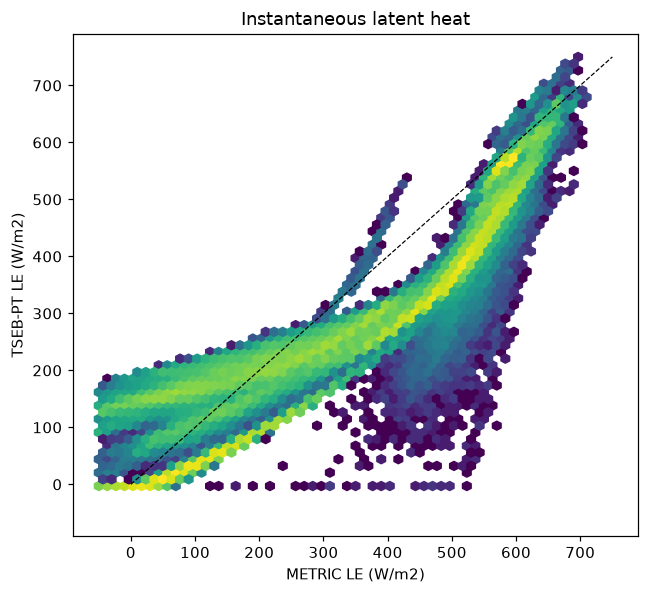

correlation of LE: 0.94


In [6]:
comp = by_group(LE_tseb=ts.le, LE_metric=metric.le, H_tseb=ts.h_s + ts.h_c, H_metric=metric.h)  # per crop group
comp["ET24 TSEB (ETrF x ETr24)"] = by_group(v=(3600 * ts.le / seb.latent_heat_of_vaporization(p["lst"]) / p["etr_inst"]).clip(0, 1.3) * p["etr_daily"])["v"]  # same daily scaling as METRIC
comp["ET24 METRIC"] = by_group(v=metric.et24)["v"]  # METRIC daily ET
display(comp.round(1))  # table
fig, ax = plt.subplots(figsize=(6, 5.5))  # one panel
ax.hexbin(metric.le.values.ravel(), ts.le.values.ravel(), gridsize=60, bins="log", extent=(-50, 750, -50, 750)); ax.plot([0, 750], [0, 750], "k--", lw=0.8)  # LE vs LE
ax.set_xlabel("METRIC LE (W/m2)"); ax.set_ylabel("TSEB-PT LE (W/m2)"); ax.set_title("Instantaneous latent heat"); plt.tight_layout(); plt.show()  # labels
print(f"correlation of LE: {float(xr.corr(metric.le, ts.le)):.2f}")  # agreement in pattern

TSEB and METRIC agree on the pattern (correlation 0.94 for LE). TSEB's LE is about 40 to 110
W m-2 lower over the crops and higher over rangeland. The levels differ for three reasons: TSEB uses
the ERA5 air temperature directly, while METRIC never uses it; TSEB caps canopy transpiration at the
Priestley-Taylor rate, which on this advective day is below what METRIC's cold anchor is allowed;
and TSEB's soil evaporation over dry land is too high, as seen above.
The next section shows how strongly the air temperature controls TSEB.

## Sensitivity to air temperature

ERA5 describes the air over a 25 km cell; the air over an irrigated orchard can be a few kelvin
cooler than over the surrounding fallow land. Shifting the air temperature by up to 3 K in each
direction shows how much that matters.

In [7]:
rows = []  # one row per shift
for dTa in (-3, -2, -1, 0, 1, 2, 3):  # air temperature shifts, K
    r = seb.tseb_pt(p["lst"], lai, t_air + dTa, a["u10"], a["ea_kpa"], p["pressure"], p["rn"], sza, hc=hc, z_u=10.0, z_t=2.0, clumping=clump)  # rerun
    g = by_group(v=r.le)["v"]  # mean LE per crop group
    rows.append({"air temperature shift (K)": dTa, "scene mean LE (W/m2)": float(r.le.mean()), **g.round(0).to_dict()})  # row
sens = pd.DataFrame(rows).set_index("air temperature shift (K)")  # table
display(sens.round(0))  # LE for each shift
base = sens.loc[0, "scene mean LE (W/m2)"]  # unshifted
print(f"scene mean LE changes by {(sens.loc[1, 'scene mean LE (W/m2)'] - base):+.0f} W/m2 per +1 K of air temperature")  # sensitivity

,scene mean LE (W/m2),Tree crops,Grapes,Annual crops,Fallow,Grass and shrubs,Developed
air temperature shift (K),,,,,,,
-3,228.0,285.0,335.0,302.0,45.0,172.0,162.0
-2,242.0,301.0,355.0,318.0,52.0,182.0,174.0
-1,255.0,316.0,373.0,333.0,61.0,192.0,186.0
0,269.0,330.0,389.0,346.0,74.0,201.0,199.0
1,281.0,343.0,402.0,357.0,89.0,211.0,212.0
2,294.0,356.0,413.0,368.0,105.0,221.0,225.0
3,306.0,368.0,423.0,377.0,123.0,230.0,237.0


scene mean LE changes by +13 W/m2 per +1 K of air temperature


A 1 K warmer air temperature lowers `Ts - Ta` and `Tc - Ta` everywhere, which reduces sensible heat
and raises LE across the scene: about 13 W m-2 per kelvin for the scene mean, roughly linearly. In
relative terms fallow land is the most sensitive: its LE nearly triples from 45 to 123 W m-2 between
-3 and +3 K. That is exactly why ALEXI and DisALEXI were developed: they
replace the air temperature with quantities a satellite can measure, and why METRIC and SEBAL
calibrate `dT` at anchors instead of using `Ta` at all.

## An optional check with pyTSEB

`pyTSEB` (`pip install pytseb`) is the reference implementation of TSEB, with series and parallel
networks, clumping models and many options. If it is installed, the cell runs its TSEB-PT on a
sample of pixels for comparison; otherwise it says so and the notebook continues.

In [8]:
try:  # pyTSEB is optional
    from pyTSEB import TSEB  # reference TSEB implementation

    print("pyTSEB", getattr(TSEB, "__version__", ""), "is installed; see its documentation for TSEB.TSEB_PT")  # available
except ImportError:  # not installed
    print("pyTSEB is not installed (pip install pytseb); the GeoLattice TSEB-PT result above stands on its own")  # skip

pyTSEB is not installed (pip install pytseb); the GeoLattice TSEB-PT result above stands on its own


## Summary and exercises

- TSEB splits radiometric temperature and net radiation between soil and canopy, starts the canopy
  at the Priestley-Taylor rate, and lowers it where the soil budget would need negative evaporation.
- Soil and canopy temperatures differed by 9 to 18 K within the vegetated crop groups.
- Transpiration dominates ET at full cover (T/ET 0.86 for tomatoes) and soil evaporation grows as
  cover falls; TSEB's soil evaporation is the least certain part (it gave dry rangeland about 165
  W m-2) because it knows nothing about how the soil was wetted.
- TSEB agreed with METRIC on the pattern of latent heat (correlation 0.94) but changed the scene mean
  LE by about 13 W m-2 per kelvin of air temperature, the sensitivity that motivated ALEXI and
  DisALEXI.
- Over tall canopies, reanalysis 2 m air temperature must be treated as air above the canopy, or the
  aerodynamic resistance is undefined.

**Exercises**

1. Rerun TSEB-PT with clumping 1.0 for every pixel. How do orchard T/ET and soil temperature change?
2. Lower `alpha_pt` from 1.26 to 1.0 (a stressed canopy). Which crops lose the most transpiration?
3. Replace the crop table heights with `hc = 0.1 + 0.5 * lai` and compare LE by crop group.
4. Run TSEB-PT on the 26 May scene, when many annual crops were young. How does the scene's T/ET
   compare with July?